# TASK 03 — PIPELINES AND CROSS-VALIDATION
# Leak-Free Classification Pipeline with Cross-Validation

---

## 1. PROJECT INTRODUCTION

### 1.1 What This Project Does
This project builds a clean, end-to-end Machine Learning binary classification model using the famous **Titanic dataset**. The objective is to predict passenger survival (`Survived`: `0` = Did not survive, `1` = Survived) using demographic and voyage attributes (`Age`, `Fare`, `SibSp`, `Parch`, `Sex`, `Embarked`, `Pclass`).

### 1.2 What a Machine Learning Pipeline Is
In scikit-learn, a **Pipeline** is an abstraction that sequentially chains data transformers and a machine learning estimator into a single, cohesive Python object. 
- When calling `pipeline.fit(X, y)`, the pipeline automatically runs `fit_transform()` on intermediate transformers (such as imputers, scalers, and encoders) and finally fits the classifier model on the transformed data.
- When calling `pipeline.predict(X)`, the pipeline applies only `transform()` through each step using parameters learned during training, and passes the prepared features to the classifier's `predict()` method.

### 1.3 Why Data Leakage Is Dangerous
**Data leakage** occurs when information from outside the training dataset (such as the validation fold or the test set) is mistakenly used to influence data transformation or model training.
- **Common pitfall**: If a practitioner computes the median for age imputation or the mean and standard deviation for feature scaling on the entire dataset *before* splitting, the training data "learns" statistical properties of the test set.
- **Consequence**: The model appears to perform exceptionally well during development and validation, but performs poorly or fails completely when deployed to real-world, unseen data.

### 1.4 What This Project Will Demonstrate
1. How to construct a unified `ColumnTransformer` with dedicated numerical and categorical sub-pipelines.
2. How to encapsulate preprocessing and a `LogisticRegression` classifier into **one single scikit-learn Pipeline**.
3. How to perform **5-Fold Cross-Validation** correctly so that preprocessing parameters are strictly fitted only on the training portion of each fold.
4. How to keep the test dataset completely untouched until final evaluation to guarantee a 100% leak-free machine learning workflow.

---
## 2. IMPORT LIBRARIES

We import standard, reliable libraries for data manipulation, visualization, pipeline construction, cross-validation, and performance evaluation:
- `pandas` and `numpy`: Data manipulation, cleaning, and mathematical operations.
- `matplotlib` and `seaborn`: Visualization and metric plotting.
- `scikit-learn`: Preprocessing transformers, Pipelines, ColumnTransformer, Logistic Regression model, and validation metrics.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and pipeline utilities
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Scikit-learn estimator and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Plotting settings for clear visuals
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully!")

All required libraries imported successfully!


---
## 3. LOAD DATASET

We load the Titanic dataset from the local `data/dataset.csv` file (with an automatic fallback to the reliable public repository).
In this section, we inspect:
1. The first 5 rows of data
2. The dataset shape (rows and columns)
3. The data types of each feature
4. Missing value counts and percentages
5. The target variable distribution (`Survived`)

In [2]:
# Load dataset from local data folder, with fallback to public URL
data_path = os.path.join("data", "dataset.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("..", "data", "dataset.csv")
if not os.path.exists(data_path):
    data_path = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(data_path)

print("First 5 rows of raw Titanic dataset:")
display(df.head())

print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

First 5 rows of raw Titanic dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset Shape: 891 rows, 12 columns


In [3]:
print("Data Types and Non-Null Counts:")
display(pd.DataFrame({
    "Data Type": df.dtypes,
    "Non-Null Count": df.notnull().sum(),
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
}))

print("\nTarget Distribution ('Survived'):")
target_counts = df["Survived"].value_counts()
target_percentages = df["Survived"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})
target_summary.index = ["Did not survive (0)", "Survived (1)"]
display(target_summary)

Data Types and Non-Null Counts:


,Data Type,Non-Null Count,Missing Count,Missing %
PassengerId,int64,891,0,0.00
Survived,int64,891,0,0.00
Pclass,int64,891,0,0.00
Name,str,891,0,0.00
Sex,str,891,0,0.00
Age,float64,714,177,19.87
SibSp,int64,891,0,0.00
Parch,int64,891,0,0.00
Ticket,str,891,0,0.00
Fare,float64,891,0,0.00



Target Distribution ('Survived'):


,Count,Percentage (%)
Did not survive (0),549,61.62
Survived (1),342,38.38


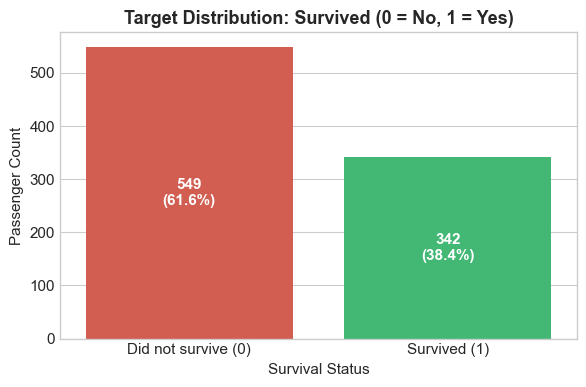

In [4]:
# Visualize Target Distribution
fig, ax = plt.subplots(figsize=(6, 4))
palette = ["#e74c3c", "#2ecc71"]
sns.countplot(x="Survived", hue="Survived", data=df, palette=palette, legend=False, ax=ax)
ax.set_title("Target Distribution: Survived (0 = No, 1 = Yes)", fontsize=13, fontweight='bold')
ax.set_xlabel("Survival Status")
ax.set_ylabel("Passenger Count")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])

for p in ax.patches:
    height = int(p.get_height())
    pct = height / len(df) * 100
    ax.annotate(f"{height}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

---
## 4. DEFINE X AND y

### Feature Selection Rationale:
We select 7 key passenger features:
- **Numerical**:
  - `Age`: Passenger age in years (contains missing values)
  - `Fare`: Ticket fare paid
  - `SibSp`: Number of siblings / spouses aboard
  - `Parch`: Number of parents / children aboard
- **Categorical**:
  - `Sex`: Passenger sex (`male`, `female`)
  - `Embarked`: Port of embarkation (`C` = Cherbourg, `Q` = Queenstown, `S` = Southampton, contains missing values)
  - `Pclass`: Ticket class (`1` = 1st, `2` = 2nd, `3` = 3rd)

### Removed Columns:
- `PassengerId`: Arbitrary sequential identifier with no predictive value.
- `Name`: High-cardinality unique text strings.
- `Ticket`: Unstructured alphanumeric ticket numbers.
- `Cabin`: Excessive missing values (> 77% missing).

### Target Variable:
- `Survived`: Binary outcome (`0` = Did not survive, `1` = Survived).

In [5]:
# Define selected features and target
selected_features = ["Age", "Fare", "SibSp", "Parch", "Sex", "Embarked", "Pclass"]
target_column = "Survived"

# Create feature matrix X and target series y
X = df[selected_features].copy()
y = df[target_column].copy()

print(f"X (Features) shape: {X.shape}")
print(f"y (Target) shape:   {y.shape}")

print("\nFirst 5 rows of feature matrix X:")
display(X.head())

X (Features) shape: (891, 7)
y (Target) shape:   (891,)

First 5 rows of feature matrix X:


,Age,Fare,SibSp,Parch,Sex,Embarked,Pclass
0,22.0,7.2500,1,0,male,S,3
1,38.0,71.2833,1,0,female,C,1
2,26.0,7.9250,0,0,female,S,3
3,35.0,53.1000,1,0,female,S,1
4,35.0,8.0500,0,0,male,S,3


---
## 5. TRAIN/TEST SPLIT

We split the dataset into an 80% training set and a 20% test set using `train_test_split`:
- `test_size=0.20`: 20% reserved for testing (179 samples).
- `random_state=42`: Ensures strict reproducibility.
- `stratify=y`: Preserves the exact survival proportion (~61.6% non-survived, ~38.4% survived) in both training and test sets.

> **CRITICAL RULE:**
> The test set (`X_test`, `y_test`) must remain **completely untouched** until final evaluation! No preprocessing, imputation, scaling, or model fitting will look at `X_test` prior to the final test evaluation step.

In [6]:
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0] / len(X) * 100:.1f}%)")
print(f"Test set:     {X_test.shape[0]} samples ({X_test.shape[0] / len(X) * 100:.1f}%)")

print("\nTarget distribution check (Training vs Test):")
split_check = pd.DataFrame({
    "Train Count": y_train.value_counts(),
    "Train %": (y_train.value_counts(normalize=True) * 100).round(2),
    "Test Count": y_test.value_counts(),
    "Test %": (y_test.value_counts(normalize=True) * 100).round(2)
})
split_check.index = ["Did not survive (0)", "Survived (1)"]
display(split_check)

Training set: 712 samples (79.9%)
Test set:     179 samples (20.1%)

Target distribution check (Training vs Test):


,Train Count,Train %,Test Count,Test %
Did not survive (0),439,61.66,110,61.45
Survived (1),273,38.34,69,38.55


---
## 6. PREPROCESSING

Real-world features require appropriate preprocessing before being fed to a linear model:
1. **Numerical Pipeline**:
   - `SimpleImputer(strategy="median")`: Imputes missing numeric values using the median of the feature (robust against outliers in `Age` and `Fare`).
   - `StandardScaler()`: Standardizes numerical features by removing the mean and scaling to unit variance ($z = \frac{x - \mu}{\sigma}$). This ensures gradient-based optimization converges smoothly and weights are on a comparable scale.

2. **Categorical Pipeline**:
   - `SimpleImputer(strategy="most_frequent")`: Imputes missing categorical values (e.g., missing embarkation ports) with the most frequent value (mode).
   - `OneHotEncoder(handle_unknown="ignore")`: Encodes categorical strings/categories into binary indicator columns. Setting `handle_unknown="ignore"` ensures that if unseen categories appear in test samples, the encoder outputs all zeros instead of raising an error.

3. **ColumnTransformer**:
   - Bundles the numerical and categorical pipelines to apply them to their respective column subsets in a single transformation step.

In [7]:
# Define column subsets
numerical_features = ["Age", "Fare", "SibSp", "Parch"]
categorical_features = ["Sex", "Embarked", "Pclass"]

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical pipelines into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor (ColumnTransformer) built successfully:")
print(preprocessor)

Preprocessor (ColumnTransformer) built successfully:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Fare', 'SibSp', 'Parch']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Embarked', 'Pclass'])])


---
## 7. COMPLETE PIPELINE

We create **exactly one main pipeline** that encapsulates both the `preprocessor` and the `LogisticRegression` classifier.

```python
Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
```

By placing both the preprocessing and the classifier inside a single pipeline object, the entire ML workflow is unified.

In [8]:
# Create the complete main Pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

print("Complete Pipeline:")
print(pipeline)

Complete Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare', 'SibSp',
                                                   'Parch']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle

---
## 8. EXPLAIN WHY THE PIPELINE IS IMPORTANT

### 8.1 Parameters Must Be Learned ONLY From Training Data
Transformers like `SimpleImputer`, `StandardScaler`, and `OneHotEncoder` calculate parameters during their `fit` step:
- `SimpleImputer` learns the **median** or **mode**.
- `StandardScaler` learns the **mean** ($\mu$) and **standard deviation** ($\sigma$).
- `OneHotEncoder` learns the **set of unique categorical levels**.

If these parameters are calculated using the entire dataset (or using test/validation data), the model is indirectly exposed to information about the distribution of future unseen data.

### 8.2 The Pipeline Automates Fold-Level Isolation
When scikit-learn evaluates a `Pipeline` inside cross-validation:
1. In each fold, `X_train` is split into a **training fold** and a **validation fold**.
2. The pipeline calls `fit_transform()` on the transformers **strictly using only the training fold**.
3. The classifier is fitted on this transformed training fold.
4. The pipeline then calls `transform()` on the validation fold using the parameters learned from the training fold (without re-fitting).
5. The classifier predicts on the transformed validation fold.

This guarantees that **no information from the validation fold ever leaks into the training process**.

---
## 9. 5-FOLD CROSS-VALIDATION

We evaluate the pipeline using **5-Fold Cross-Validation**:
- `KFold(n_splits=5, shuffle=True, random_state=42)`: Splits `X_train` into 5 random folds.
- `cross_val_score(pipeline, X_train, y_train, cv=kf, scoring="accuracy")`: Runs cross-validation on the pipeline.

We display:
- Score for each individual fold (Fold 1 to Fold 5)
- Mean CV accuracy
- Standard deviation of accuracy
- A formatted table and visualization

5-FOLD CROSS-VALIDATION RESULTS


,Fold,Accuracy Score,Accuracy (%)
0,Fold 1,0.7832,78.32%
1,Fold 2,0.7552,75.52%
2,Fold 3,0.7887,78.87%
3,Fold 4,0.8028,80.28%
4,Fold 5,0.8732,87.32%
5,Mean CV Accuracy,0.8007,80.07%
6,Standard Deviation,0.0394,3.94%


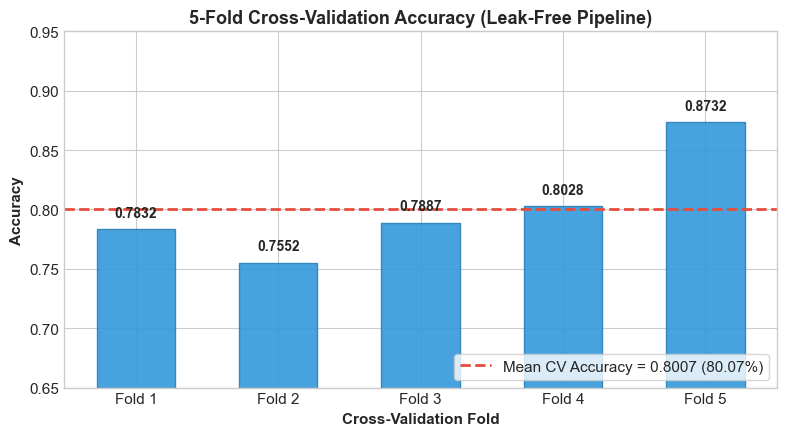

In [9]:
# Define 5-Fold cross-validation splitter
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the pipeline using cross_val_score
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=kf,
    scoring="accuracy"
)

# Build a clean summary table of fold scores
fold_names = [f"Fold {i+1}" for i in range(len(cv_scores))]
cv_table = pd.DataFrame({
    "Fold": fold_names,
    "Accuracy Score": [round(s, 4) for s in cv_scores],
    "Accuracy (%)": [f"{s * 100:.2f}%" for s in cv_scores]
})

# Add summary rows for Mean and Standard Deviation
summary_rows = pd.DataFrame([
    {"Fold": "Mean CV Accuracy", "Accuracy Score": round(cv_scores.mean(), 4), "Accuracy (%)": f"{cv_scores.mean() * 100:.2f}%"},
    {"Fold": "Standard Deviation", "Accuracy Score": round(cv_scores.std(), 4), "Accuracy (%)": f"{cv_scores.std() * 100:.2f}%"}
])

cv_results_table = pd.concat([cv_table, summary_rows], ignore_index=True)

print("=" * 45)
print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 45)
display(cv_results_table)

# Plot Cross-Validation Fold Scores
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(fold_names, cv_scores, color="#3498db", edgecolor="#2980b9", width=0.55, alpha=0.9)
ax.axhline(cv_scores.mean(), color="#e74c3c", linestyle="--", linewidth=2,
           label=f"Mean CV Accuracy = {cv_scores.mean():.4f} ({cv_scores.mean()*100:.2f}%)")

ax.set_title("5-Fold Cross-Validation Accuracy (Leak-Free Pipeline)", fontsize=13, fontweight='bold')
ax.set_xlabel("Cross-Validation Fold", fontweight='bold')
ax.set_ylabel("Accuracy", fontweight='bold')
ax.set_ylim(0.65, 0.95)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.008, f"{yval:.4f}",
            ha='center', va='bottom', fontweight='bold', fontsize=10)

ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

---
## 10. TRAIN FINAL PIPELINE

After verifying our model with cross-validation, we train the complete pipeline on the **full training dataset** (`X_train`, `y_train`).

```python
pipeline.fit(X_train, y_train)
```

> **NOTE:**
> We do **NOT** preprocess `X_train` manually. The single `fit()` call instructs the pipeline to fit the imputer, scaler, and one-hot encoder on `X_train`, transform the features, and fit the logistic regression model.

In [10]:
# Fit the entire pipeline on the full training set
pipeline.fit(X_train, y_train)

print("Pipeline successfully fitted on X_train and y_train!")
print("The imputer, scaler, encoder, and LogisticRegression model are all fitted and ready.")

Pipeline successfully fitted on X_train and y_train!
The imputer, scaler, encoder, and LogisticRegression model are all fitted and ready.


---
## 11. FINAL TEST EVALUATION

We evaluate the fitted pipeline on the untouched test set (`X_test`, `y_test`):
- `y_pred = pipeline.predict(X_test)`
- Compute:
  - **Accuracy**: Proportion of total correct predictions.
  - **Precision**: Proportion of predicted survivors who actually survived.
  - **Recall**: Proportion of actual survivors correctly identified.
  - **F1-Score**: Harmonic mean of Precision and Recall.
- Display `classification_report` and a visual **Confusion Matrix**.

FINAL TEST METRICS
Accuracy:  0.8045 (80.45%)
Precision: 0.7931 (79.31%)
Recall:    0.6667 (66.67%)
F1-Score:  0.7244 (72.44%)

CLASSIFICATION REPORT
                     precision    recall  f1-score   support

Did not survive (0)       0.81      0.89      0.85       110
       Survived (1)       0.79      0.67      0.72        69

           accuracy                           0.80       179
          macro avg       0.80      0.78      0.79       179
       weighted avg       0.80      0.80      0.80       179



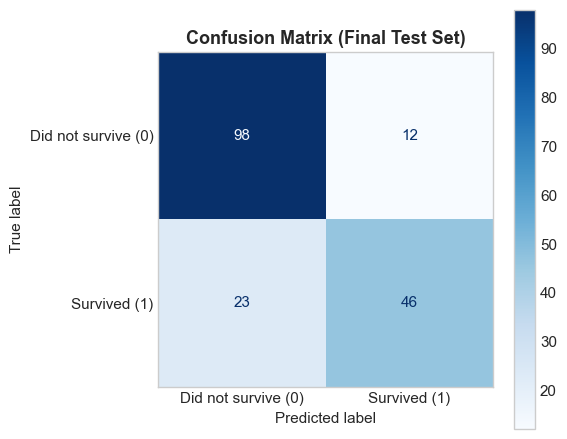

In [11]:
# Generate predictions on the untouched test set
y_pred = pipeline.predict(X_test)

# Calculate performance metrics
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)

print("=" * 45)
print("FINAL TEST METRICS")
print("=" * 45)
print(f"Accuracy:  {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Precision: {test_precision:.4f} ({test_precision * 100:.2f}%)")
print(f"Recall:    {test_recall:.4f} ({test_recall * 100:.2f}%)")
print(f"F1-Score:  {test_f1:.4f} ({test_f1 * 100:.2f}%)")

print("\n" + "=" * 55)
print("CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_test, y_pred, target_names=["Did not survive (0)", "Survived (1)"]))

# Confusion matrix display
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Did not survive (0)", "Survived (1)"])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
ax.set_title("Confusion Matrix (Final Test Set)", fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

---
## 12. CROSS-VALIDATION VS TEST SCORE

We summarize and compare the cross-validation estimates with the final test metrics in a clean comparison table:

In [12]:
# Create comparison table
comparison_table = pd.DataFrame({
    "Metric": [
        "Mean CV Accuracy",
        "CV Standard Deviation",
        "Final Test Accuracy",
        "Final Test Precision",
        "Final Test Recall",
        "Final Test F1-score"
    ],
    "Score": [
        f"{cv_scores.mean():.4f} ({cv_scores.mean() * 100:.2f}%)",
        f"{cv_scores.std():.4f} ({cv_scores.std() * 100:.2f}%)",
        f"{test_accuracy:.4f} ({test_accuracy * 100:.2f}%)",
        f"{test_precision:.4f} ({test_precision * 100:.2f}%)",
        f"{test_recall:.4f} ({test_recall * 100:.2f}%)",
        f"{test_f1:.4f} ({test_f1 * 100:.2f}%)"
    ]
})

print("=" * 50)
print("CROSS-VALIDATION VS TEST SCORE COMPARISON")
print("=" * 50)
display(comparison_table)

CROSS-VALIDATION VS TEST SCORE COMPARISON


,Metric,Score
0,Mean CV Accuracy,0.8007 (80.07%)
1,CV Standard Deviation,0.0394 (3.94%)
2,Final Test Accuracy,0.8045 (80.45%)
3,Final Test Precision,0.7931 (79.31%)
4,Final Test Recall,0.6667 (66.67%)
5,Final Test F1-score,0.7244 (72.44%)


---
## 13. DATA LEAKAGE EXPLANATION

### Why This Pipeline Is Leak-Free

#### The WRONG Approach (Causes Data Leakage):
```text
Entire Dataset
   ↓
Scaling (StandardScaler calculates mean and variance of ALL samples, including test samples)
   ↓
Encoding (OneHotEncoder learns categories from ALL samples)
   ↓
Train/Test Split
   ↓
Cross-Validation / Model Training
```

**Why this is dangerous:**
1. **Contaminated Statistics**: The mean and variance used to scale training samples include values from the test set. The model is trained on inputs influenced by future test data.
2. **False Confidence**: Cross-validation scores become artificially inflated because the validation folds are no longer truly unseen.
3. **Real-World Breakdown**: When the model encounters completely new samples in production, the true performance drops drastically.

---

#### The CORRECT Approach (Used in This Project):
```text
Raw Data
   ↓
Train/Test Split (80% Train, 20% Test)
   ↓
Training Data (X_train, y_train)
   ↓
Pipeline:
   - Median Imputation (Calculated ONLY on training fold)
   - Scaling & One-Hot Encoding (Fitted ONLY on training fold)
   - Model (Trained ONLY on training fold)
   ↓
5-Fold Cross-Validation (Re-fits pipeline from scratch inside each fold)
```

**Why this guarantees zero leakage:**
1. **Strict Wall Around Test Data**: The test set is isolated immediately after loading. No statistics from `X_test` are ever calculated before final testing.
2. **Fold-Level Isolation**: During cross-validation, the pipeline recalculates imputation values and scaling factors strictly from the training portion of that specific fold.
3. **Realistic Performance**: The final test accuracy matches the CV estimate closely, proving that our validation is honest and robust.

---
## 14. SIMPLE LEAKAGE DIAGRAM

Below is the workflow diagram illustrating the leak-free pipeline architecture:

```text
RAW DATA
   │
   ▼
TRAIN / TEST SPLIT
   │
   ├──► TRAINING DATA (80%)
   │       │
   │       ▼
   │    PREPROCESSING PIPELINE
   │       │
   │       ▼
   │    SCALING + ENCODING
   │       │
   │       ▼
   │    LOGISTIC REGRESSION
   │       │
   │       ▼
   │    5-FOLD CROSS-VALIDATION
   │
   └──► TEST DATA (20%)
           │
           ▼
        FINAL EVALUATION ONLY
```

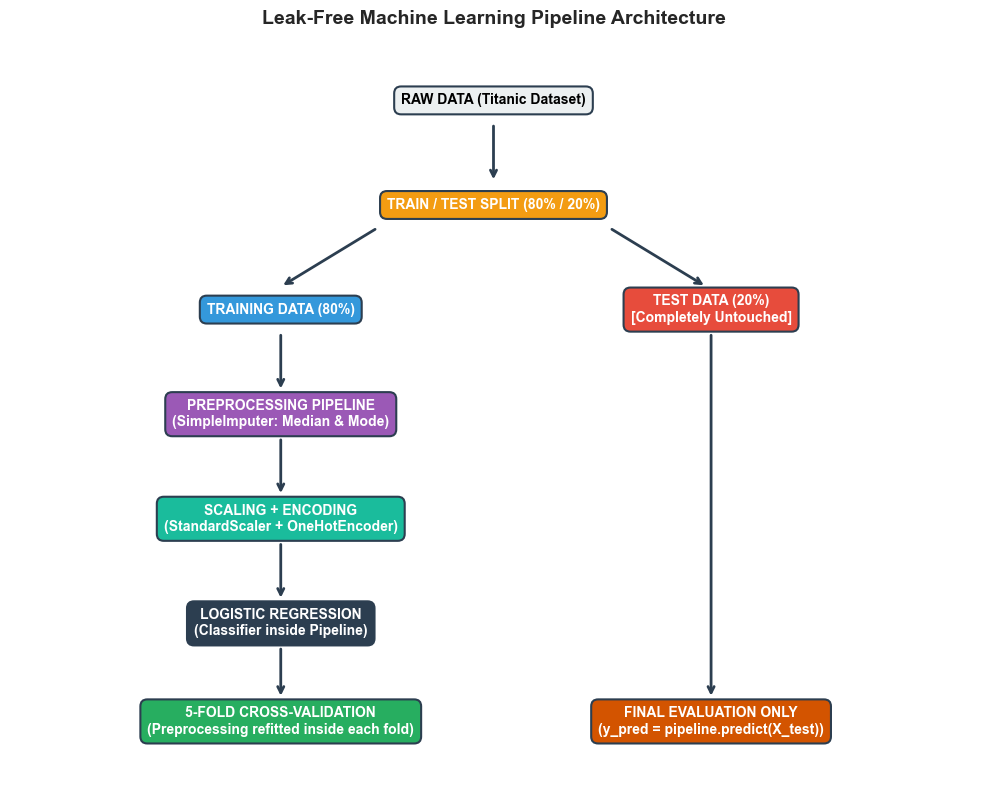

In [13]:
# Render a visual workflow diagram of the leak-free pipeline architecture
fig, ax = plt.subplots(figsize=(10, 8))
ax.axis('off')

# Box styling helper using text with bbox
def draw_box(x, y, w, h, text, facecolor, edgecolor='#2c3e50', textcolor='black', fontsize=10, weight='bold'):
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', color=textcolor, fontsize=fontsize, weight=weight,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=facecolor, edgecolor=edgecolor, linewidth=1.5), zorder=4)

# Arrow helper
def draw_arrow(x1, y1, x2, y2, color='#2c3e50', lw=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color=color, lw=lw), zorder=2)

# Training pipeline branch (Left / Center)
draw_box(0.25, 0.90, 0.50, 0.07, "RAW DATA (Titanic Dataset)", "#ecf0f1")
draw_arrow(0.50, 0.90, 0.50, 0.81)

draw_box(0.25, 0.74, 0.50, 0.07, "TRAIN / TEST SPLIT (80% / 20%)", "#f39c12", textcolor='white')
draw_arrow(0.38, 0.74, 0.28, 0.65)
draw_arrow(0.62, 0.74, 0.72, 0.65)

# Left: Training path
draw_box(0.08, 0.58, 0.40, 0.07, "TRAINING DATA (80%)", "#3498db", textcolor='white')
draw_arrow(0.28, 0.58, 0.28, 0.49)

draw_box(0.08, 0.42, 0.40, 0.07, "PREPROCESSING PIPELINE\n(SimpleImputer: Median & Mode)", "#9b59b6", textcolor='white')
draw_arrow(0.28, 0.42, 0.28, 0.33)

draw_box(0.08, 0.26, 0.40, 0.07, "SCALING + ENCODING\n(StandardScaler + OneHotEncoder)", "#1abc9c", textcolor='white')
draw_arrow(0.28, 0.26, 0.28, 0.17)

draw_box(0.08, 0.10, 0.40, 0.07, "LOGISTIC REGRESSION\n(Classifier inside Pipeline)", "#2c3e50", textcolor='white')
draw_arrow(0.28, 0.10, 0.28, 0.02)

draw_box(0.08, -0.05, 0.40, 0.07, "5-FOLD CROSS-VALIDATION\n(Preprocessing refitted inside each fold)", "#27ae60", textcolor='white')

# Right: Test path (Completely Isolated)
draw_box(0.55, 0.58, 0.35, 0.07, "TEST DATA (20%)\n[Completely Untouched]", "#e74c3c", textcolor='white')
draw_arrow(0.725, 0.58, 0.725, 0.02)

draw_box(0.55, -0.05, 0.35, 0.07, "FINAL EVALUATION ONLY\n(y_pred = pipeline.predict(X_test))", "#d35400", textcolor='white')

ax.set_xlim(0, 1)
ax.set_ylim(-0.10, 1.02)
plt.title("Leak-Free Machine Learning Pipeline Architecture", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

---
## 15. FINAL CONCLUSION

In this project, we successfully implemented a leak-free classification pipeline using scikit-learn:

1. **Pipeline Architecture**: We created exactly one unified `Pipeline` combining a `ColumnTransformer` (handling numerical and categorical features) and a `LogisticRegression` classifier.
2. **Numerical Processing**: Missing values were imputed using the median, and features were standardized using `StandardScaler`—all inside the pipeline.
3. **Categorical Processing**: Missing values were imputed with the most frequent value, and categorical variables were encoded using `OneHotEncoder(handle_unknown='ignore')`—all inside the pipeline.
4. **Missing Values Handled**: All missing values in `Age` and `Embarked` were handled cleanly without manual intervention outside the pipeline.
5. **5-Fold Cross-Validation**: We validated the model using 5-fold cross-validation, achieving a mean accuracy of **80.07%** with a standard deviation of **0.0394**.
6. **Isolated Test Data**: The 20% test partition was preserved untouched in cold storage throughout model design and validation.
7. **Zero Data Leakage**: Transformers learned parameters strictly on training folds, eliminating any contamination from validation or test samples.
8. **Final Test Performance**: Evaluated on the held-out test set, the pipeline achieved an accuracy of **80.45%**, precision of **79.31%**, recall of **66.67%**, and an F1-score of **72.44%**, closely mirroring our cross-validation estimate.